In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
## Create sample ticket data

In [3]:

tickets = pd.DataFrame({
    "ticket_id": [101, 102, 103, 104, 105, 106, 107, 108],
    "complaint": [
        "I was charged twice and need help immediately",
        "I cannot access my account and I am upset",
        "I want a refund for my order",
        "The application crashes when I open it",
        "Please tell me more about your product",
        "The product quality is very bad",
        "My account has been hacked",
        "I have a question about my invoice"
    ],
    "category": [
        "Billing and Payments",
        "Account Access",
        "Refund Requests",
        "Technical Issues",
        "Product or Service Complaints",
        "Product or Service Complaints",
        "Account Access",
        "Billing and Payments"
    ],
    "sentiment": [
        "Negative",
        "Negative",
        "Neutral",
        "Negative",
        "Positive",
        "Negative",
        "Negative",
        "Neutral"
    ]
})

display(tickets)


,ticket_id,complaint,category,sentiment
0,101,I was charged twice and need help immediately,Billing and Payments,Negative
1,102,I cannot access my account and I am upset,Account Access,Negative
2,103,I want a refund for my order,Refund Requests,Neutral
3,104,The application crashes when I open it,Technical Issues,Negative
4,105,Please tell me more about your product,Product or Service Complaints,Positive
5,106,The product quality is very bad,Product or Service Complaints,Negative
6,107,My account has been hacked,Account Access,Negative
7,108,I have a question about my invoice,Billing and Payments,Neutral


In [5]:

# Urgency-related keywords
URGENT_KEYWORDS = [
    "urgent",
    "immediately",
    "fraud",
    "hacked",
    "unauthorized access",
    "charged twice",
    "account compromised",
    "data breach"
]

# Categories that require extra attention
HIGH_RISK_CATEGORIES = [
    "Account Access",
    "Technical Issues"
]

# Categories that normally receive medium priority
MEDIUM_CATEGORIES = [
    "Billing and Payments",
    "Refund Requests"
]

print("Priority rules configured.")
print("Urgency keywords:", URGENT_KEYWORDS)


Priority rules configured.
Urgency keywords: ['urgent', 'immediately', 'fraud', 'hacked', 'unauthorized access', 'charged twice', 'account compromised', 'data breach']


In [ ]:
# CREATE THE PRIORITY RECOMMENDATION FUNCTION

In [6]:

def recommend_priority(category, sentiment, complaint):
    """
    Recommend priority using predefined business rules.

    High:
        An urgency keyword is present, or
        negative sentiment occurs with a high-risk category.

    Medium:
        Sentiment is negative, or
        the category is billing or refund.

    Low:
        No higher-priority rule applies.
    """

    text = str(complaint).lower()
    category = str(category).strip()
    sentiment = str(sentiment).strip().title()

    # Rule 1: Urgency keywords take precedence
    matched_keywords = [
        word for word in URGENT_KEYWORDS
        if word in text
    ]

    if matched_keywords:
        reason = (
            "Urgency keyword detected: "
            + ", ".join(matched_keywords)
        )
        return "High", reason

    # Rule 2: Negative sentiment with a high-risk category
    if (
        sentiment == "Negative"
        and category in HIGH_RISK_CATEGORIES
    ):
        return (
            "High",
            "Negative sentiment with a high-risk category"
        )

    # Rule 3: Negative sentiment
    if sentiment == "Negative":
        return "Medium", "Negative customer sentiment"

    # Rule 4: Billing and refund categories
    if category in MEDIUM_CATEGORIES:
        return "Medium", "Billing or refund issue"

    # Rule 5: Default priority
    return "Low", "No higher-priority rule was triggered"


print("Priority recommendation function created.")


Priority recommendation function created.


Apply the rules to every ticket

In [7]:
results = tickets.apply(
    lambda row: recommend_priority(
        row["category"],
        row["sentiment"],
        row["complaint"],
    ),
    axis=1

)

tickets["suggested_priority"] = results.apply(
    lambda result: result[0]
)

tickets["priority_reason"] = results.apply(
    lambda result: result[1]
)

display(tickets)

,ticket_id,complaint,category,sentiment,suggested_priority,priority_reason
0,101,I was charged twice and need help immediately,Billing and Payments,Negative,High,"Urgency keyword detected: immediately, charged..."
1,102,I cannot access my account and I am upset,Account Access,Negative,High,Negative sentiment with a high-risk category
2,103,I want a refund for my order,Refund Requests,Neutral,Medium,Billing or refund issue
3,104,The application crashes when I open it,Technical Issues,Negative,High,Negative sentiment with a high-risk category
4,105,Please tell me more about your product,Product or Service Complaints,Positive,Low,No higher-priority rule was triggered
5,106,The product quality is very bad,Product or Service Complaints,Negative,Medium,Negative customer sentiment
6,107,My account has been hacked,Account Access,Negative,High,Urgency keyword detected: hacked
7,108,I have a question about my invoice,Billing and Payments,Neutral,Medium,Billing or refund issue


Check the priority distribution

Priority Distribution


,Number of Tickets
suggested_priority,
High,4
Medium,3
Low,1


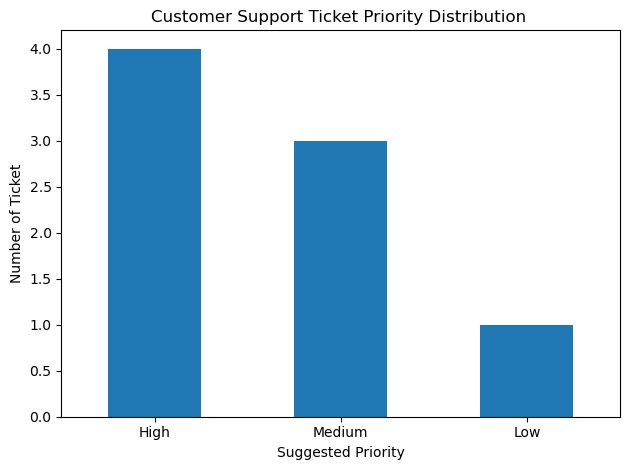

In [8]:
priority_order = ["High", "Medium", "Low"]

priority_counts = (
    tickets["suggested_priority"]
    .value_counts()
    .reindex(priority_order, fill_value=0)

)

print("Priority Distribution")
display(priority_counts.rename("Number of Tickets").to_frame())

priority_counts.plot(
    kind="bar",
    title="Customer Support Ticket Priority Distribution ",
    xlabel="Suggested Priority",
    ylabel="Number of Ticket",
    rot=0
)

plt.tight_layout()
plt.show()

Allow a  support agent to review a ticket

In [11]:

ticket_id = int(input("Enter ticket ID to review (101-108): "))

matching_rows = tickets.index[
    tickets["ticket_id"] == ticket_id
]

if len(matching_rows) == 0:
    print("Ticket ID not found.")
else:
    idx = matching_rows[0]

    print("\nTicket ID:", tickets.loc[idx, "ticket_id"])
    print("Complaint:", tickets.loc[idx, "complaint"])
    print("Category:", tickets.loc[idx, "category"])
    print("Sentiment:", tickets.loc[idx, "sentiment"])
    print("Suggested Priority:", tickets.loc[idx, "suggested_priority"])
    print("Reason:", tickets.loc[idx, "priority_reason"])

    print("\nThe agent can accept or override the suggestion.")

    agent_priority = input(
        "Enter final priority (Low/Medium/High): "
    ).strip().title()

    if agent_priority in ["Low", "Medium", "High"]:
        tickets.loc[idx, "agent_priority"] = agent_priority

        if agent_priority != tickets.loc[idx, "suggested_priority"]:
            tickets.loc[idx, "agent_changed_priority"] = True
            print("The agent changed the suggested priority.")
        else:
            tickets.loc[idx, "agent_changed_priority"] = False
            print("The agent accepted the suggested priority.")

        print("Final priority:", agent_priority)

    else:
        print("Invalid priority. Please enter Low, Medium, or High.")



Ticket ID: 102
Complaint: I cannot access my account and I am upset
Category: Account Access
Sentiment: Negative
Suggested Priority: High
Reason: Negative sentiment with a high-risk category

The agent can accept or override the suggestion.
The agent accepted the suggested priority.
Final priority: High


In [12]:

review_columns = [
    "ticket_id",
    "complaint",
    "suggested_priority",
    "priority_reason",
    "agent_priority",
    "agent_changed_priority"
]

display(tickets[review_columns])


,ticket_id,complaint,suggested_priority,priority_reason,agent_priority,agent_changed_priority
0,101,I was charged twice and need help immediately,High,"Urgency keyword detected: immediately, charged...",NaN,NaN
1,102,I cannot access my account and I am upset,High,Negative sentiment with a high-risk category,High,False
2,103,I want a refund for my order,Medium,Billing or refund issue,NaN,NaN
3,104,The application crashes when I open it,High,Negative sentiment with a high-risk category,NaN,NaN
4,105,Please tell me more about your product,Low,No higher-priority rule was triggered,NaN,NaN
5,106,The product quality is very bad,Medium,Negative customer sentiment,NaN,NaN
6,107,My account has been hacked,High,Urgency keyword detected: hacked,NaN,NaN
7,108,I have a question about my invoice,Medium,Billing or refund issue,NaN,NaN


Save result to CSV

In [13]:

output_file = "ticket_priority_results.csv"

tickets.to_csv(output_file, index=False)

print(f"Results saved to: {output_file}")


Results saved to: ticket_priority_results.csv


Verify the saved file

In [14]:

saved_tickets = pd.read_csv("ticket_priority_results.csv")

print("Saved file loaded successfully.")
print("Total tickets:", len(saved_tickets))

display(saved_tickets.head())


Saved file loaded successfully.
Total tickets: 8


,ticket_id,complaint,category,sentiment,suggested_priority,priority_reason,agent_priority,agent_changed_priority
0,101,I was charged twice and need help immediately,Billing and Payments,Negative,High,"Urgency keyword detected: immediately, charged...",NaN,NaN
1,102,I cannot access my account and I am upset,Account Access,Negative,High,Negative sentiment with a high-risk category,High,False
2,103,I want a refund for my order,Refund Requests,Neutral,Medium,Billing or refund issue,NaN,NaN
3,104,The application crashes when I open it,Technical Issues,Negative,High,Negative sentiment with a high-risk category,NaN,NaN
4,105,Please tell me more about your product,Product or Service Complaints,Positive,Low,No higher-priority rule was triggered,NaN,NaN
